# Getting started with eitkit

This tutorial walks through a complete difference-EIT experiment: build a mesh,
define a conductivity phantom, simulate electrode voltages, compute the
Jacobian, and reconstruct the conductivity change with Tikhonov and
total-variation (TV) regularization. It then covers three things you need
before using eitkit on your own problems: choosing the regularization
parameter without knowing the true image, testing a method fairly, and
preparing measured data.

Run the cells from top to bottom; the whole notebook takes well under a
minute. Install the package first, from the repository root:

```bash
pip install -e ".[dev]"
```

For the mathematics behind each step, see `THEORY.md` and
`docs/eitkit-tech-note.pdf`.

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

import eitkit
from eitkit.forward import compute_jacobian, simulate
from eitkit.inverse import choose_lambda, tikhonov_solve, tv_solve
from eitkit.mesh import make_circle_mesh, place_electrodes
from eitkit.protocol import add_noise, adjacent_pattern, measurement_pairs
from eitkit.utils import make_phantom, plot_conductivity, plot_mesh, plot_voltages

plt.rcParams.update({"figure.dpi": 110})
print("eitkit", eitkit.__version__)


def rel_error(estimate, truth):
    "Relative L2 error, the figure of merit used throughout."
    return np.linalg.norm(estimate - truth) / np.linalg.norm(truth)

eitkit 0.2.0


## 2. The mesh and the electrodes

eitkit works on the unit disc. `make_circle_mesh` builds a triangular mesh
with target edge length `h0`. The boundary is resolved by nodes at most `h0`
apart, and one boundary node sits exactly at each electrode angle
$2\pi\ell/L$, starting on the positive $x$-axis and running counterclockwise.
`place_electrodes` returns those nodes in order.

Electrodes follow the *gap model*: each electrode is a single boundary node,
and current enters and leaves the body only there.

604 nodes, 1126 triangles, 80 boundary nodes, mean edge length 0.075


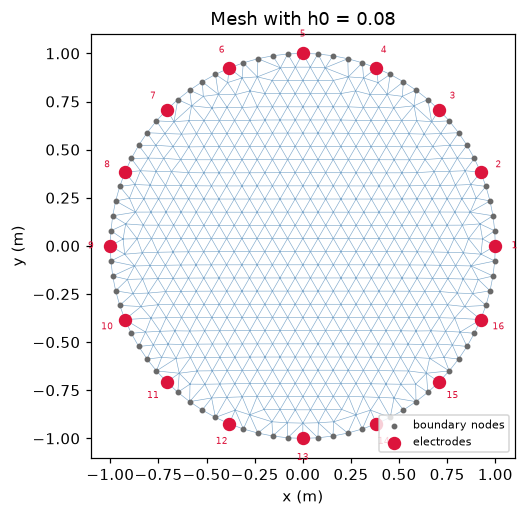

In [2]:
N_ELECTRODES = 16
mesh = make_circle_mesh(n_electrodes=N_ELECTRODES, h0=0.08, seed=42)
electrodes = place_electrodes(mesh, n_electrodes=N_ELECTRODES)
print(f"{mesh.n_nodes} nodes, {mesh.n_elements} triangles, "
      f"{mesh.n_boundary_nodes} boundary nodes, mean edge length {mesh.h_mean:.3f}")

fig, ax = plot_mesh(mesh, elec_config=electrodes, title="Mesh with h0 = 0.08")
plt.show()

**Choosing `h0`.** A smaller `h0` gives a more accurate forward model and a
larger problem. Electrode voltages converge at roughly second order: against
the exact solution for a uniform disc, the relative error is about 0.9% at
`h0 = 0.1` and 0.15% at `h0 = 0.05` (run `scripts/verify_convergence.py` to
reproduce this). The Jacobian has one column per triangle, so the cost of the
reconstruction grows like $1/h_0^2$:

In [3]:
for h0 in (0.12, 0.08, 0.05):
    t0 = time.perf_counter()
    m = make_circle_mesh(n_electrodes=N_ELECTRODES, h0=h0, seed=42)
    print(f"h0 = {h0:.2f}: {m.n_elements:5d} triangles "
          f"(mesh built in {time.perf_counter() - t0:.2f} s)")

h0 = 0.12:   502 triangles (mesh built in 0.40 s)


h0 = 0.08:  1126 triangles (mesh built in 0.84 s)


h0 = 0.05:  2890 triangles (mesh built in 2.35 s)


## 3. A conductivity phantom

A phantom is an array with one conductivity per triangle. `make_phantom`
starts from a uniform background and adds inclusions, each given as a
dictionary. The supported shapes are `circle`, `ellipse`, `rectangle`, `ring`,
and `triangle`; `help(make_phantom)` lists their parameters. A triangle
belongs to an inclusion if its centroid does.

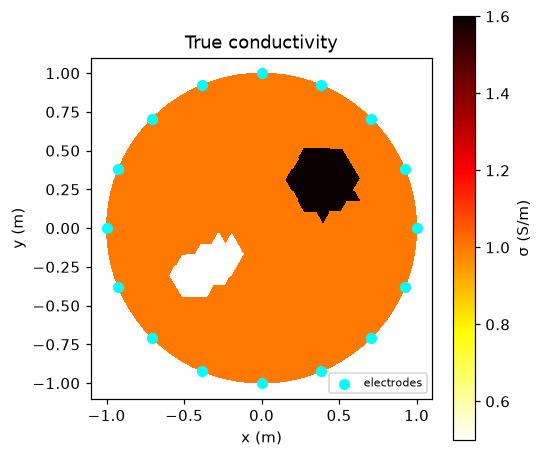

In [4]:
SIGMA_BG = 1.0
inclusions = [
    {"shape": "circle", "cx": 0.40, "cy": 0.30, "r": 0.22, "sigma": 1.6},
    {"shape": "ellipse", "cx": -0.35, "cy": -0.25, "a": 0.25, "b": 0.14,
     "theta": 0.6, "sigma": 0.5},
]
sigma_true = make_phantom(mesh, inclusions, sigma_background=SIGMA_BG)
sigma_ref = np.full(mesh.n_elements, SIGMA_BG)
delta_true = sigma_true - sigma_ref

fig, ax = plot_conductivity(mesh, sigma_true, elec_config=electrodes,
                            title="True conductivity")
plt.show()

## 4. The measurement protocol

With *adjacent drive*, current is injected between neighbouring electrodes
$k$ and $k+1$, and voltages are measured between every other pair of
neighbouring electrodes that does not include a driven one. That gives 13
measurements for each of the 16 drive steps, 208 in total. Each row of
`meas_pairs` is `[drive step, + electrode, - electrode]`.

In [5]:
drive_pairs = adjacent_pattern(N_ELECTRODES)
meas_pairs = measurement_pairs(N_ELECTRODES)
print("drive pairs:", drive_pairs.shape, "  first three:", drive_pairs[:3].tolist())
print("measurements:", meas_pairs.shape)
print(meas_pairs[:4])

drive pairs: (16, 2)   first three: [[0, 1], [1, 2], [2, 3]]
measurements: (208, 3)
[[0 2 3]
 [0 3 4]
 [0 4 5]
 [0 5 6]]


## 5. Simulating difference voltages

Difference EIT works with changes. `simulate` solves the forward problem for
the target conductivity and for the reference `sigma0`, and returns
$\delta V = V(\sigma) - V(\sigma_0)$, one value per measurement. `add_noise`
then adds white Gaussian noise with a given signal-to-noise ratio over the
whole vector.

||dV|| = 3.087e-02, noise norm = 1.541e-04


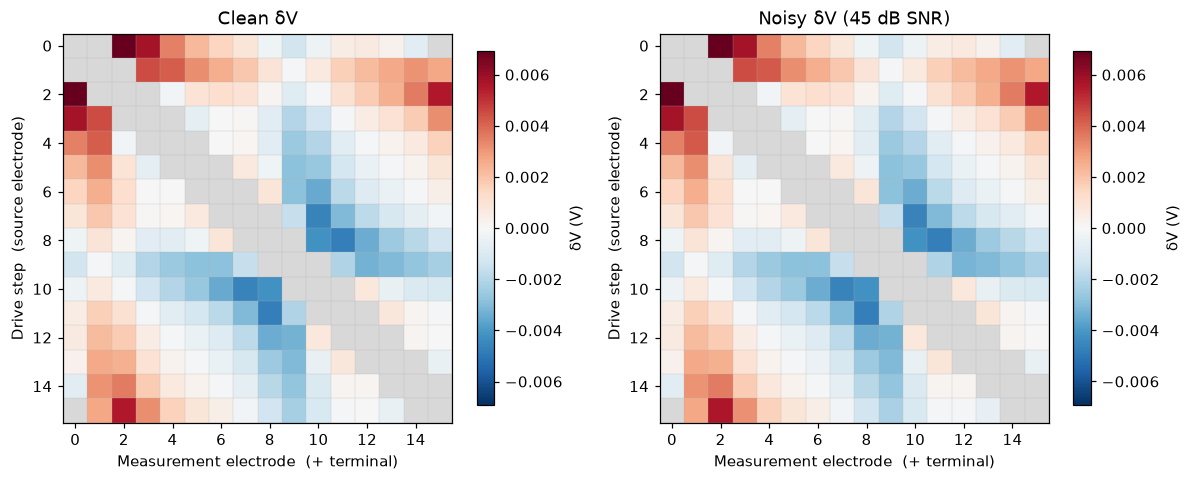

In [6]:
dV_clean = simulate(mesh, electrodes, sigma_true, drive_pairs, meas_pairs,
                    current=1.0, sigma0=SIGMA_BG)
SNR_DB = 45.0
dV = add_noise(dV_clean, snr_db=SNR_DB, rng=42)
print(f"||dV|| = {np.linalg.norm(dV_clean):.3e}, "
      f"noise norm = {np.linalg.norm(dV - dV_clean):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_voltages(meas_pairs, dV_clean, n_electrodes=N_ELECTRODES, ax=axes[0],
              title="Clean δV")
plot_voltages(meas_pairs, dV, n_electrodes=N_ELECTRODES, ax=axes[1],
              title=f"Noisy δV ({SNR_DB:.0f} dB SNR)")
fig.tight_layout()
plt.show()

## 6. The Jacobian and the linear model

Both reconstruction methods linearize around the reference conductivity:
$\delta V \approx J\,\delta\sigma$, where the Jacobian $J$ has one row per
measurement and one column per triangle and is computed with the adjoint
method. Before reconstructing, check how good the linear model is for your
contrast:

In [7]:
J = compute_jacobian(mesh, electrodes, sigma_ref, drive_pairs, meas_pairs, current=1.0)
lin_err = rel_error(J @ delta_true, dV_clean)
print("J shape:", J.shape)
print(f"linearization error ||J dsigma - dV|| / ||dV|| = {lin_err:.3f}")

J shape: (208, 1126)
linearization error ||J dsigma - dV|| / ||dV|| = 0.269


The linear model misses about 27% of the data for these contrasts (1.6 and
0.5 S/m against a 1 S/m background), and larger contrasts make it worse. A
single linearized step cannot reproduce the full contrast; that needs an
iterative (Gauss-Newton type) scheme, which eitkit does not provide yet.

The column norms of $J$, divided by the triangle areas, show where the
measurements are sensitive. Sensitivity is highest next to the electrodes and
falls by more than an order of magnitude towards the centre, which is the main reason EIT
images are blurrier in the middle:

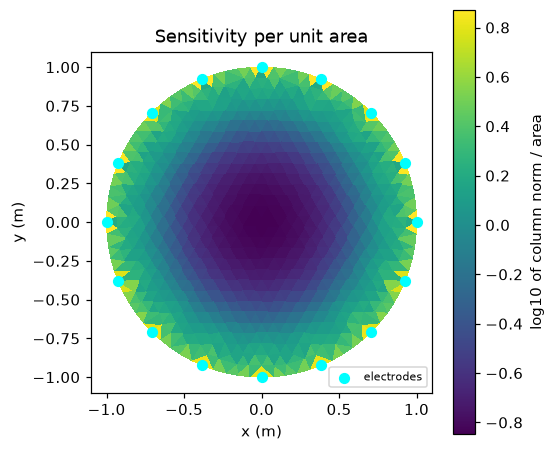

In [8]:
sensitivity = np.linalg.norm(J, axis=0) / mesh.areas
fig, ax = plot_conductivity(mesh, np.log10(sensitivity), cmap="viridis",
                            elec_config=electrodes, title="Sensitivity per unit area")
fig.axes[-1].set_ylabel("log10 of column norm / area")
plt.show()

## 7. Tikhonov reconstruction

Tikhonov regularization solves

$$\min_{\delta\sigma}\ \|J\delta\sigma - \delta V\|^2 + \lambda\|\delta\sigma\|^2 .$$

`choose_lambda` evaluates a range of $\lambda$ values and returns the corner of
the L-curve: the point of maximum curvature of $\log\|J\delta\sigma_\lambda -
\delta V\|$ plotted against $\log\|\delta\sigma_\lambda\|$.

L-curve corner: lambda = 2.28e-09
Tikhonov relative error: 0.689


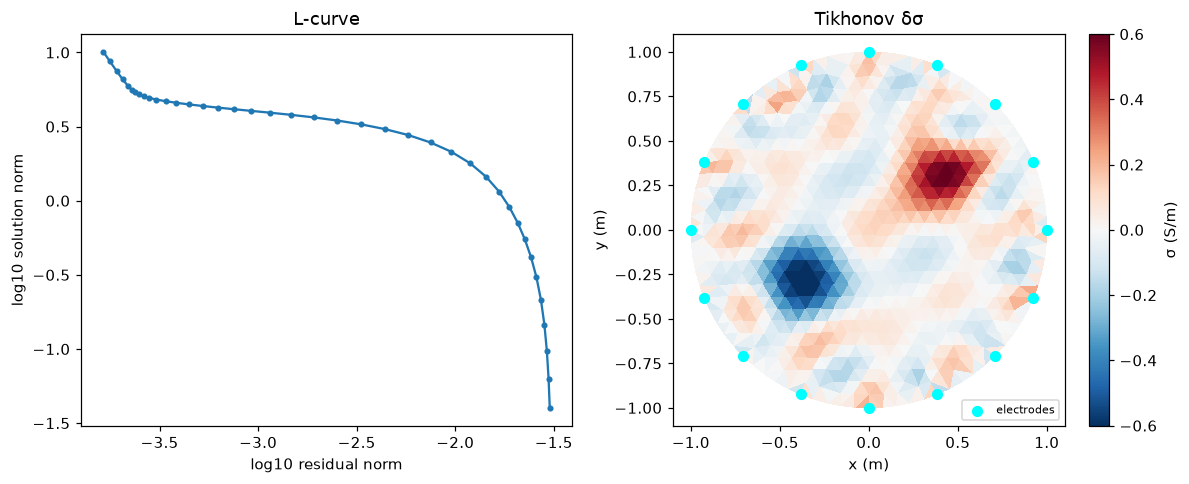

In [9]:
lam_lcurve, log_res, log_norm = choose_lambda(J, dV, n_points=40)
ds_tik = tikhonov_solve(J, dV, lambda_=lam_lcurve)
print(f"L-curve corner: lambda = {lam_lcurve:.2e}")
print(f"Tikhonov relative error: {rel_error(ds_tik, delta_true):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(log_res, log_norm, "o-", ms=3)
axes[0].set_xlabel("log10 residual norm")
axes[0].set_ylabel("log10 solution norm")
axes[0].set_title("L-curve")
vmax = np.abs(delta_true).max()
plot_conductivity(mesh, ds_tik, ax=axes[1], cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                  elec_config=electrodes, title="Tikhonov δσ")
fig.tight_layout()
plt.show()

## 8. Total-variation reconstruction

TV regularization,

$$\min_{\delta\sigma}\ \tfrac12\|J\delta\sigma - \delta V\|^2 + \alpha\|D\,\delta\sigma\|_1 ,$$

where $D$ takes the jump across each interior edge between neighbouring
triangles, favours piecewise-constant images with sharp edges. `tv_solve`
solves it with ADMM; `rho="auto"` scales the ADMM penalty to the problem.
ADMM converges slowly: it stops when the primal and dual residuals are small,
here after about 3300 iterations (about a second).

TV relative error: 0.395


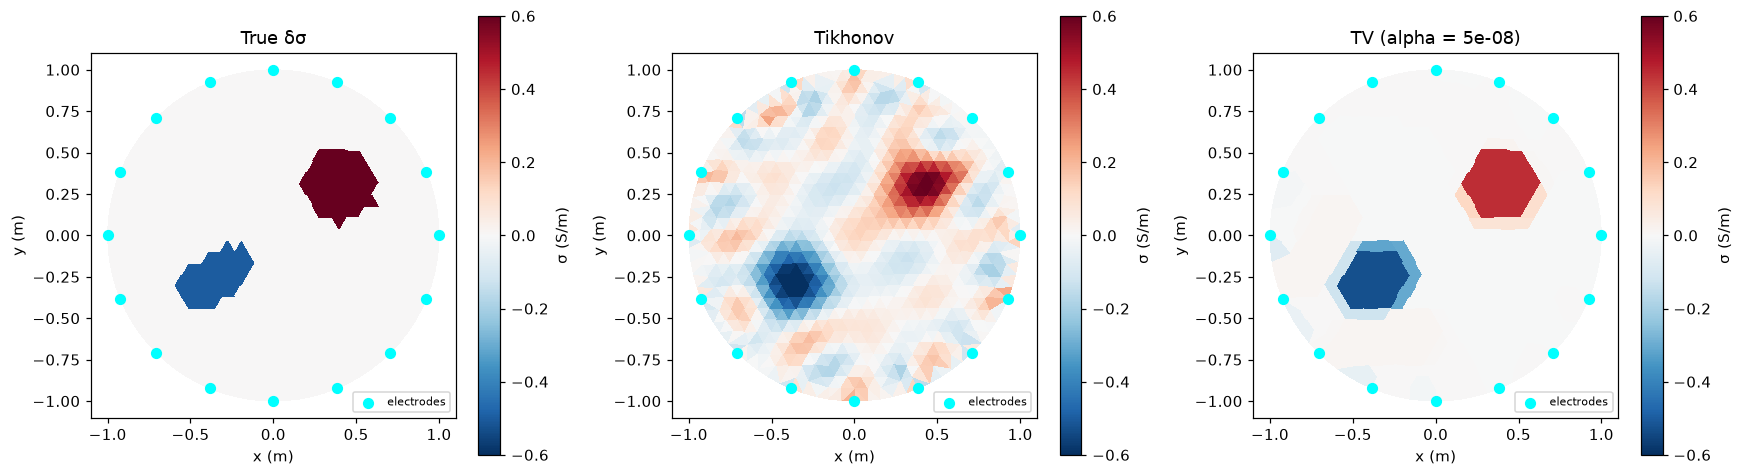

In [10]:
ALPHA_TV = 5e-8
ds_tv = tv_solve(J, dV, alpha=ALPHA_TV, mesh=mesh)
print(f"TV relative error: {rel_error(ds_tv, delta_true):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, img, title in zip(axes, [delta_true, ds_tik, ds_tv],
                          ["True δσ", "Tikhonov", f"TV (alpha = {ALPHA_TV:.0e})"]):
    plot_conductivity(mesh, img, ax=ax, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                      elec_config=electrodes, title=title)
fig.tight_layout()
plt.show()

TV recovers the two inclusions with sharp edges and a flat background. Both
methods underestimate the contrast: a single linearized step cannot reach
$+0.6$ and $-0.5$ S/m, and the regularization pulls values towards zero.

## 9. Choosing parameters without the true image

Above, we could compute the error because we know `delta_true`. With measured
data you cannot, so you need a rule that uses the data alone. A sweep over
$\lambda$ shows how much the choice matters, and how close the L-curve gets:

best lambda = 6.3e-08 (error 0.575); L-curve lambda = 2.3e-09 (error 0.689)


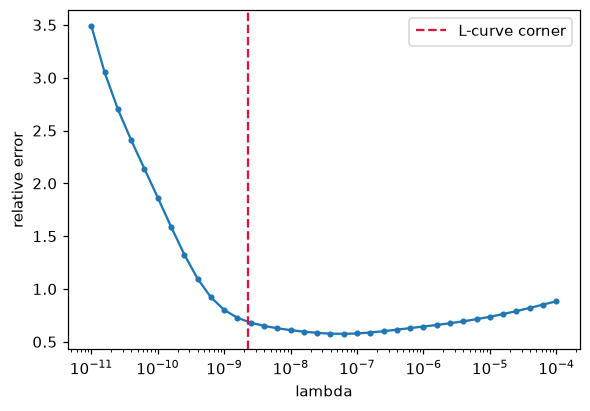

In [11]:
lambdas = np.logspace(-11, -4, 36)
errors = [rel_error(tikhonov_solve(J, dV, lambda_=lam), delta_true) for lam in lambdas]
best = lambdas[int(np.argmin(errors))]
print(f"best lambda = {best:.1e} (error {min(errors):.3f}); "
      f"L-curve lambda = {lam_lcurve:.1e} "
      f"(error {rel_error(tikhonov_solve(J, dV, lambda_=lam_lcurve), delta_true):.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(lambdas, errors, "o-", ms=3)
ax.axvline(lam_lcurve, color="crimson", ls="--", label="L-curve corner")
ax.set_xlabel("lambda")
ax.set_ylabel("relative error")
ax.legend()
plt.show()

Here the L-curve corner ($2.3\times10^{-9}$) lies below the best value
($6.3\times10^{-8}$): it regularizes too little, and its error (0.69) is
about 20% above the best possible (0.58). That is typical of a heuristic
rule. Treat its $\lambda$ as a starting point, and check that the image stays
similar when $\lambda$ changes by a factor of 10 in either direction.

You may know the *discrepancy principle*: choose $\lambda$ so that the residual
$\|J\delta\sigma_\lambda - \delta V\|$ matches the noise level. It fails here,
and the reason is instructive. By reciprocity, only 104 of the 208
measurements are independent, so $J$ has rank 104. The clean data lie
entirely in the range of $J$: the linearization error can be fitted exactly
by some other $\delta\sigma$, so the residual cannot tell model error from
signal. Most of the noise, on the other hand, lies outside the range of $J$
and can never be fitted:

In [12]:
U, s, _ = np.linalg.svd(J, full_matrices=False)
rank = int((s > s[0] * 1e-10).sum())
P = U[:, :rank]                                   # orthonormal basis of range(J)


def outside(v):
    "Fraction of the norm of v that lies outside the range of J."
    return np.linalg.norm(v - P @ (P.T @ v)) / np.linalg.norm(v)


noise = dV - dV_clean
print(f"rank of J: {rank} of {J.shape[0]} rows")
print(f"clean data outside range(J): {outside(dV_clean):.1e}")
print(f"noise outside range(J):      {outside(noise):.2f}")

target = np.linalg.norm(noise)
lams = np.logspace(-13, -6, 141)
residuals = [np.linalg.norm(J @ tikhonov_solve(J, dV, lambda_=lam) - dV) for lam in lams]
lam_dp = lams[np.argmin(np.abs(np.array(residuals) - target))]
print(f"discrepancy principle: lambda = {lam_dp:.1e}, "
      f"relative error {rel_error(tikhonov_solve(J, dV, lambda_=lam_dp), delta_true):.2f}")

rank of J: 104 of 208 rows
clean data outside range(J): 1.6e-14
noise outside range(J):      0.71


discrepancy principle: lambda = 8.9e-11, relative error 1.93


Setting the residual equal to the noise level therefore forces the residual
below what the model can explain honestly: $\lambda$ falls to about
$10^{-10}$ and the reconstruction is dominated by fitted noise (relative error
about 1.9). The principle would need the noise level of the part of the data
that $J$ can fit, which is rarely known. Here the L-curve is the safer rule.

The same care applies to $\alpha$ for TV. A short sweep (smaller $\alpha$
converges more slowly, so this cell takes about 15 seconds):

In [13]:
for alpha in (1e-8, 2e-8, 5e-8, 1e-7, 2e-7):
    ds = tv_solve(J, dV, alpha=alpha, mesh=mesh)
    print(f"alpha = {alpha:.0e}: relative error {rel_error(ds, delta_true):.3f}")

alpha = 1e-08: relative error 0.436


alpha = 2e-08: relative error 0.404


alpha = 5e-08: relative error 0.395


alpha = 1e-07: relative error 0.419


alpha = 2e-07: relative error 0.470


## 10. Testing fairly: avoid the inverse crime

So far the data were simulated on the same mesh that is used for the
reconstruction. This *inverse crime* hides the discretization error and makes
methods look better than they are. A fairer test simulates the data on a finer
mesh. Every mesh places the electrodes at the same angles, so data from any
mesh fit the reconstruction mesh's Jacobian.

In [14]:
fine = make_circle_mesh(n_electrodes=N_ELECTRODES, h0=0.04, seed=7)
fine_electrodes = place_electrodes(fine, n_electrodes=N_ELECTRODES)
sigma_fine = make_phantom(fine, inclusions, sigma_background=SIGMA_BG)
dV_fine = add_noise(simulate(fine, fine_electrodes, sigma_fine, drive_pairs, meas_pairs,
                             current=1.0, sigma0=SIGMA_BG), snr_db=SNR_DB, rng=42)
print(f"fine mesh: {fine.n_elements} triangles; reconstruction mesh: {mesh.n_elements}")

ds_tik_fine = tikhonov_solve(J, dV_fine, lambda_=lam_lcurve)
ds_tv_fine = tv_solve(J, dV_fine, alpha=ALPHA_TV, mesh=mesh)
print(f"{'':10s}{'same mesh':>12s}{'fine-mesh data':>16s}")
print(f"{'Tikhonov':10s}{rel_error(ds_tik, delta_true):12.3f}{rel_error(ds_tik_fine, delta_true):16.3f}")
print(f"{'TV':10s}{rel_error(ds_tv, delta_true):12.3f}{rel_error(ds_tv_fine, delta_true):16.3f}")

fine mesh: 4506 triangles; reconstruction mesh: 1126


             same mesh  fine-mesh data
Tikhonov         0.689           0.659
TV               0.395           0.396


Here the errors hardly change: Tikhonov is even slightly better with the
fine-mesh data, and TV is the same. Since version 0.2.0 the forward model is
accurate at `h0 = 0.08` (under 1% voltage error against the exact solution),
so the discretization error is small next to the linearization and
regularization errors. The check costs one extra simulation, so repeat it
whenever you change the mesh size, the electrode model, or the forward solver.

## 11. Using your own measurements

To reconstruct measured data, the experiment has to match the model:

1. **Geometry and protocol.** 16 small electrodes, equally spaced on a
   circular boundary, with adjacent drive and adjacent measurement. Electrode
   0 is at angle 0 and the numbering runs counterclockwise; use the
   `start_angle` argument of `place_electrodes` if your electrode 0 is
   elsewhere.
2. **Ordering.** Build `dV` in the order of `meas_pairs`:
   `dV[i] = V_frame[i] - V_reference[i]`, where row `i` of `meas_pairs` gives
   the drive step and the electrode pair. Many systems store a full 16 x 16
   voltage matrix per frame; select the 208 entries from it.
3. **Scale.** The model is two-dimensional and linear in $\delta\sigma$, so a
   constant scale mismatch between your data and the model scales the
   reconstructed $\delta\sigma$ by the same constant without changing its
   shape. Calibrate with a known inclusion if you need absolute values, and
   choose $\lambda$ on the data you actually reconstruct.

A template:

```python
V_ref = np.loadtxt("reference_frame.txt")   # 208 values, in meas_pairs order
V_obj = np.loadtxt("object_frame.txt")
dV_measured = V_obj - V_ref
lam, _, _ = choose_lambda(J, dV_measured)
ds = tikhonov_solve(J, dV_measured, lambda_=lam)
plot_conductivity(mesh, ds, cmap="RdBu_r", title="Reconstructed δσ")
```

## Where to go next

- `THEORY.md` and `docs/eitkit-tech-note.pdf`: the model, the algorithms,
  and the verification results.
- `examples/01_reconstruction_demo.ipynb`: a configurable demo with preset
  phantoms.
- `scripts/`: verification scripts for each module, including the
  convergence study.